# **Operational Fulfillment Analysis**

In [1]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [3]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

## 1. Load Only Relevant Columns

In [4]:
OPERATIONAL_COLUMNS = [
    # ORDER STATUS
    'order_status',

    # LOCATION
    'country',
    'shipping_country',

    # SHIPPING
    'shipping_method',
    'shipping_cost_usd',
    'shipping_cost_percent',
    'delivery_days',
    'delivery_speed',
    'shipment_type',

    # CUSTOMER EXPERIENCE
    'rating',

    # FINANCIAL IMPACT
    'net_revenue_usd',
    'profit_usd',
]

In [5]:
operational_df = ecommerce_df[OPERATIONAL_COLUMNS].copy()

In [6]:
operational_df.sample(10)

,order_status,country,shipping_country,shipping_method,shipping_cost_usd,shipping_cost_percent,delivery_days,delivery_speed,shipment_type,rating,net_revenue_usd,profit_usd
826274,Completed,Italy,Italy,Express,1.65,1.14,3,Fast,Domestic,4,144.59,40.95
84395,Completed,United States,United States,Next Day,9.71,18.81,2,Fast,Domestic,5,51.61,12.86
875347,Completed,Germany,Germany,Next Day,19.29,4.51,11,Slow,Domestic,4,427.41,114.99
596131,Completed,France,France,Express,6.03,0.86,3,Fast,Domestic,1,705.18,301.02
637685,Completed,Italy,Italy,Economy,15.40,2.97,7,Standard,Domestic,4,518.02,242.26
857172,Completed,Belgium,Belgium,Express,13.41,7.87,7,Standard,Domestic,1,170.30,92.44
63142,Completed,France,France,Next Day,11.42,13.40,9,Slow,Domestic,2,85.24,38.28
49649,Completed,Canada,Canada,Express,6.69,1.98,11,Slow,Domestic,1,337.85,147.98
993598,Completed,Canada,Canada,Next Day,1.98,0.69,1,Fast,Domestic,3,288.19,112.60
642144,Completed,France,France,Standard,7.47,18.74,14,Slow,Domestic,4,39.86,22.15


## 2. Operational Overview (KPIs)

In [7]:
total_orders = operational_df.shape[0]

completed_orders = (
    operational_df['order_status'].eq('Completed').sum()
)

returned_orders = (
    operational_df['order_status'].eq('Returned').sum()
)

cancelled_orders = (
    operational_df['order_status'].eq('Cancelled').sum()
)

processing_orders = (
    operational_df['order_status'].eq('Processing').sum()
)

pending_orders = (
    operational_df['order_status'].eq('Pending').sum()
)

completion_rate = completed_orders / total_orders * 100
return_rate = returned_orders / total_orders * 100
cancellation_rate = cancelled_orders / total_orders * 100

avg_delivery_days = operational_df['delivery_days'].mean()
avg_shipping_cost = operational_df['shipping_cost_usd'].mean()
avg_rating = operational_df['rating'].mean()

In [8]:
print(f"Total Orders          : {total_orders:,}")
print(f"Completion Rate       : {completion_rate:.2f}%")
print(f"Return Rate           : {return_rate:.2f}%")
print(f"Cancellation Rate     : {cancellation_rate:.2f}%")
print(f"Average Delivery Days : {avg_delivery_days:.2f}")
print(f"Average Shipping Cost : ${avg_shipping_cost:,.2f}")
print(f"Average Rating        : {avg_rating:.2f}")

Total Orders          : 1,000,123
Completion Rate       : 70.01%
Return Rate           : 9.99%
Cancellation Rate     : 5.02%
Average Delivery Days : 7.51
Average Shipping Cost : $12.50
Average Rating        : 3.00


## 3. Order Fulfillment Performance

### 3.1 Order Status Distribution

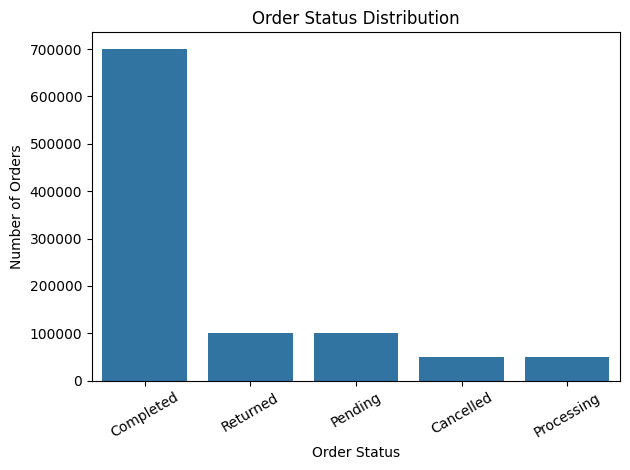

In [9]:
status_counts = (
    operational_df['order_status']
    .value_counts()
    .sort_values(ascending=False)
)

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Delivery Performance

### 4.1 Distribution of Delivery Days

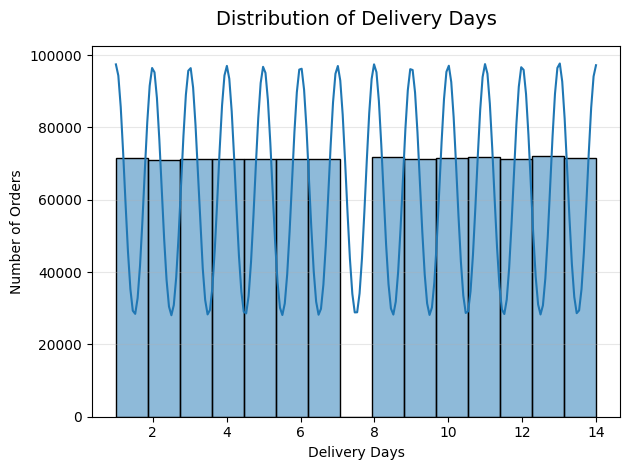

In [18]:
sns.histplot(
    data=operational_df,
    x='delivery_days',
    bins=15,
    kde=True
)

plt.title('Distribution of Delivery Days', fontsize=14, pad=15)
plt.xlabel('Delivery Days')
plt.ylabel('Number of Orders')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2 Delivery Speed Distribution

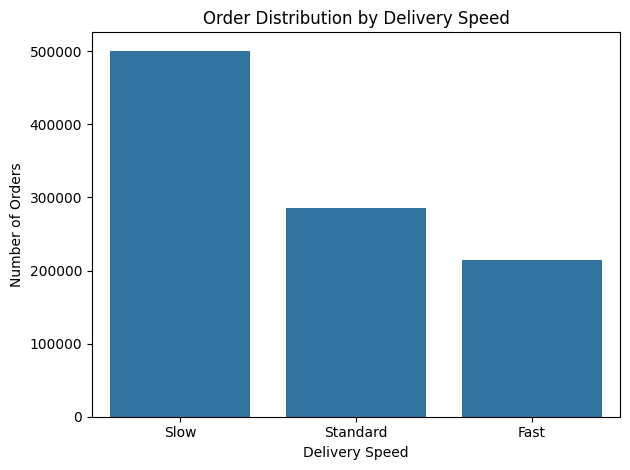

In [11]:
speed_counts = operational_df['delivery_speed'].value_counts()

sns.barplot(
    x=speed_counts.index,
    y=speed_counts.values
)

plt.title('Order Distribution by Delivery Speed')
plt.xlabel('Delivery Speed')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

### 4.3 Delivery Days by Shipping Method

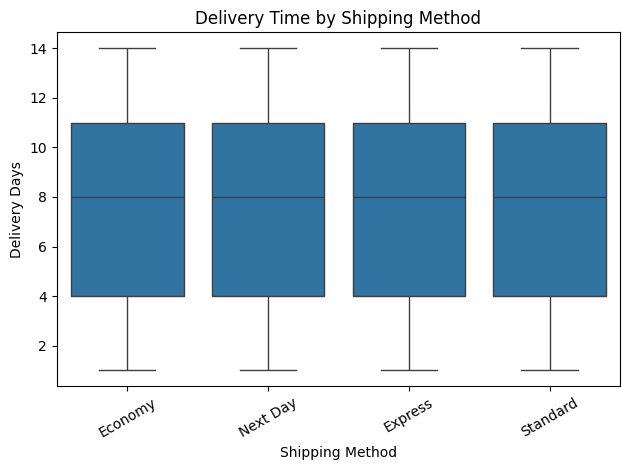

In [12]:
sns.boxplot(
    data=operational_df,
    x='shipping_method',
    y='delivery_days'
)

plt.title('Delivery Time by Shipping Method')
plt.xlabel('Shipping Method')
plt.ylabel('Delivery Days')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Shipping Cost Analysis

### 5.1 Shipping Cost Distribution

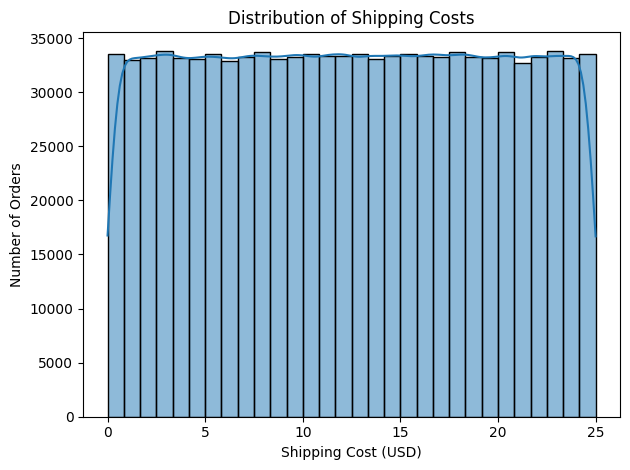

In [13]:
sns.histplot(
    data=operational_df,
    x='shipping_cost_usd',
    bins=30,
    kde=True
)

plt.title('Distribution of Shipping Costs')
plt.xlabel('Shipping Cost (USD)')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

### 5.2 Shipping Cost by Shipping Method

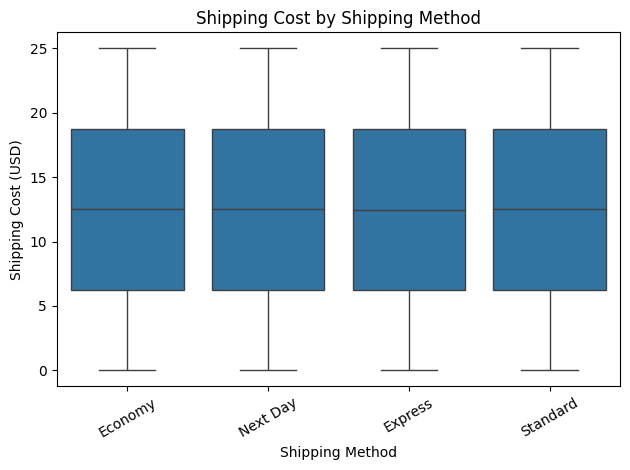

In [14]:
sns.boxplot(
    data=operational_df,
    x='shipping_method',
    y='shipping_cost_usd'
)

plt.title('Shipping Cost by Shipping Method')
plt.xlabel('Shipping Method')
plt.ylabel('Shipping Cost (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Delivery Performance vs Customer Experience

### 6.1 Delivery Days vs Rating

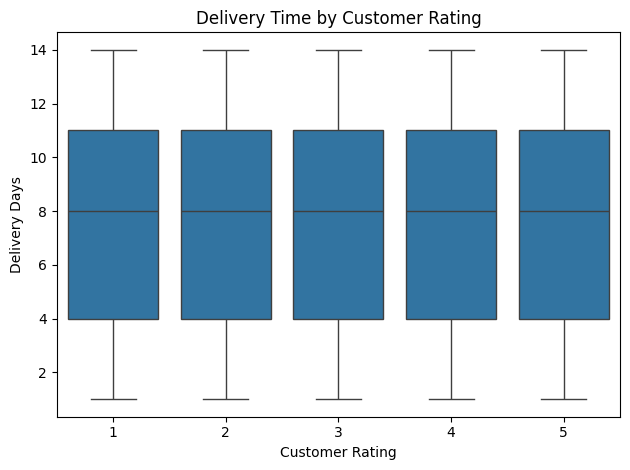

In [15]:
sns.boxplot(
    data=operational_df,
    x='rating',
    y='delivery_days'
)

plt.title('Delivery Time by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Delivery Days')
plt.tight_layout()
plt.show()

## 7. Operational Performance by Country

### 7.1 Average Delivery Days by Country

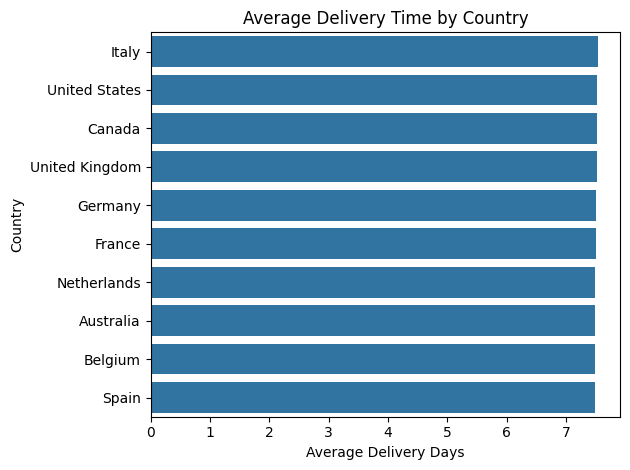

In [16]:
country_delivery = (
    operational_df
    .groupby('country')['delivery_days']
    .mean()
    .sort_values(ascending=False)
)

sns.barplot(
    x=country_delivery.values,
    y=country_delivery.index
)

plt.title('Average Delivery Time by Country')
plt.xlabel('Average Delivery Days')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## 8. Operational Profitability

### 8.1 Delivery Speed vs Profit Margin

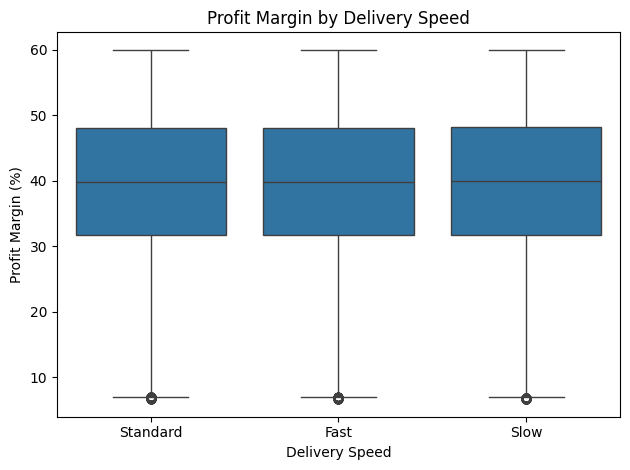

In [17]:
sns.boxplot(
    data=ecommerce_df[
        ['delivery_speed', 'profit_margin_percent']
    ],
    x='delivery_speed',
    y='profit_margin_percent'
)

plt.title('Profit Margin by Delivery Speed')
plt.xlabel('Delivery Speed')
plt.ylabel('Profit Margin (%)')
plt.tight_layout()
plt.show()